# C1 — HSV + Linear SVM

Notebook này chạy thử cấu hình `configs/experiments/c1_hsv_svm.yaml` từ đầu đến cuối:
đọc dataset cục bộ → trích xuất HSV (32 chiều) → chọn C trên validation → đánh giá test một lần → xuất kết quả.

**Lưu ý:** phần trích xuất HSV viết trong notebook này là bản tạm để kiểm tra chuỗi dữ liệu.
Bản chính thức thuộc nhóm đặc trưng (`features/`). Không đưa code trong notebook vào `src/`.

Cách chạy: chọn kernel `cs231` (môi trường `.venv`), rồi **Restart & Run All** từ trên xuống.
Cần đã chạy `scripts/download_dataset.py` và `scripts/prepare_data.py`.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.svm import LinearSVC

from material_classification.data.cache import build_cache, cache_dir, cache_signature, load_cache
from material_classification.data.dataset import (
    check_dataset_schema,
    dataset_root,
    load_minc_dataset,
)
from material_classification.data.transforms import ensure_rgb_uint8, resize_rgb, to_hsv
from material_classification.utils import (
    REPO_ROOT,
    git_info,
    load_default_config,
    local_path,
    read_yaml,
    utc_now,
    write_json,
)

# Nạp lại .env mỗi lần chạy cell để cập nhật đường dẫn trong kernel đang mở.
load_dotenv(REPO_ROOT / ".env", override=True)
cfg = load_default_config()
c1 = read_yaml(REPO_ROOT / "configs" / "experiments" / "c1_hsv_svm.yaml")
assert c1["representation"]["hsv"] is True and c1["representation"]["hog_scales"] == []
assert c1["classifier"]["type"] == "linear_svm"

# Tham số bộ phân loại đọc từ configs/experiments/c1_hsv_svm.yaml (Chương 3, mục 8.2).
SEED = c1["experiment"]["seed"]
SVM = c1["classifier"]
C_GRID = SVM["C_grid"]
assert c1["evaluation"]["selection_metric"] == "macro_f1"
CLASS_NAMES = cfg["dataset"]["class_names"]
N_CLASSES = len(CLASS_NAMES)
print("Config:", c1["experiment"]["name"], "| revision:", cfg["dataset"]["revision"][:10])

c:\Users\ASUS\Documents\Các môn CS\CV\Đồ án\Code\minc-material-classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Config: c1_hsv_svm | revision: 5ac92ad1af


## 1. Đọc dataset cục bộ

In [2]:
dataset_path = dataset_root()
print("DATASET_ROOT:", dataset_path)
ds = load_minc_dataset(dataset_path)
check_dataset_schema(ds, cfg)
{split: len(ds[split]) for split in ds}

FileNotFoundError: Chưa có dataset cục bộ tại C:\Users\ASUS\Documents\Các môn CS\CV\Đồ án\Code\minc-material-classification\data\minc-2500. Chạy: uv run python scripts/download_dataset.py

## 2. Trích xuất HSV (bản tạm trong notebook)

Resize trực tiếp từ RGB gốc bằng INTER_AREA, histogram 16/8/8 bins, L1 từng kênh, nối thành 32 chiều.

In [ ]:
HSV_RANGES = (180, 256, 256)  # miền OpenCV uint8: H ∈ [0, 179], S và V ∈ [0, 255]


def extract_hsv_c1(rgb, features_cfg):
    hsv_cfg = features_cfg["hsv"]
    hsv = to_hsv(resize_rgb(ensure_rgb_uint8(rgb), hsv_cfg["image_size"]))
    parts = []
    for channel, (n_bins, upper) in enumerate(zip(hsv_cfg["bins"], HSV_RANGES, strict=True)):
        hist, _ = np.histogram(hsv[..., channel], bins=n_bins, range=(0, upper))
        hist = hist.astype(np.float64)
        parts.append(hist / hist.sum())
    return {"hsv": np.concatenate(parts).astype(np.float32)}


# Kiểm tra nhanh trên một ảnh trước khi trích xuất cả tập
sample_rgb = np.asarray(ds["train"][0]["image"].convert("RGB"), dtype=np.uint8)
probe = extract_hsv_c1(sample_rgb, cfg["features"])["hsv"]
assert probe.shape == (32,) and np.isfinite(probe).all()
assert np.allclose([probe[:16].sum(), probe[16:24].sum(), probe[24:].sum()], 1.0, atol=1e-5)
print("Kiểm tra ảnh mẫu OK, shape:", probe.shape)

Kiểm tra ảnh mẫu OK, shape: (32,)


## 3. Ghi cache HSV (chỉ C1)

Cache đặt riêng dưới `CACHE_ROOT/c1_hsv_only` để không lẫn với cache đầy đủ của nhóm đặc trưng.

In [ ]:
C1_CACHE_ROOT = local_path("CACHE_ROOT", "./cache") / "c1_hsv_only"
cache_path = cache_dir(cfg, C1_CACHE_ROOT)

if (cache_path / "metadata.json").exists():
    print("Dùng lại cache:", cache_path)
else:
    start = time.perf_counter()
    build_cache(ds, cfg, cache_path, extract_hsv_c1)
    print(f"Trích xuất xong sau {time.perf_counter() - start:.0f} giây")

data = load_cache(cfg, cache_path)
{split: data[split]["hsv"].shape for split in data}

Dùng lại cache: D:\StupidCode\CS231\material-classification\cache\c1_hsv_only\minc2500_split1\7fd9821315aa0bb7


{'train': (48875, 32), 'validation': (2875, 32), 'test': (5750, 32)}

## 4. Chuẩn hóa L2 và chuẩn bị ma trận

C1 dùng HSV đã chuẩn hóa L2 theo từng mẫu, không fit thống kê từ train.

In [ ]:
def l2_rows(X):
    X = np.asarray(X, dtype=np.float32)
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-8)


X_train, X_val, X_test = (l2_rows(data[s]["hsv"]) for s in ("train", "validation", "test"))
y_train, y_val, y_test = (data[s]["labels"] for s in ("train", "validation", "test"))
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)

train (48875, 32) | val (2875, 32) | test (5750, 32)


## 5. Chọn C trên validation

Fit trên train, chọn C theo Macro-F1 trên validation. Hòa điểm giữ ứng viên đứng trước.

In [ ]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=list(range(N_CLASSES)), average="macro", zero_division=0)


candidates = []
best = None
for C in C_GRID:
    model = LinearSVC(
        C=C,
        penalty=SVM["penalty"],
        loss=SVM["loss"],
        max_iter=SVM["max_iter"],
        tol=SVM["tol"],
        random_state=SEED,
    )
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    val_pred = model.predict(X_val)
    score = macro_f1(y_val, val_pred)
    candidates.append(
        {
            "C": C,
            "val_macro_f1": round(float(score), 4),
            "val_accuracy": round(float(accuracy_score(y_val, val_pred)), 4),
            "convergence_warnings": sum(issubclass(w.category, ConvergenceWarning) for w in caught),
            "fit_seconds": round(fit_seconds, 1),
        }
    )
    if best is None or score > best["score"]:
        best = {"C": C, "score": score, "model": model, "val_pred": val_pred}

pd.DataFrame(candidates)

,C,val_macro_f1,val_accuracy,convergence_warnings,fit_seconds
0,0.01,0.1359,0.1791,0,2.7
1,0.10,0.1389,0.1826,0,4.0
2,1.00,0.1368,0.1816,0,5.0
3,10.00,0.1370,0.1816,0,5.0


## 6. Đánh giá test một lần

Cấu hình đã chốt ở bước 5. Không quay lại chỉnh C theo điểm test.

In [ ]:
test_pred = best["model"].predict(X_test)
labels = list(range(N_CLASSES))
report = classification_report(
    y_test, test_pred, labels=labels, target_names=CLASS_NAMES, output_dict=True, zero_division=0
)
test_accuracy = float(accuracy_score(y_test, test_pred))
test_macro_f1 = float(report["macro avg"]["f1-score"])
print(
    f"Chọn C = {best['C']} | Test Accuracy = {test_accuracy:.4f} "
    f"| Test Macro-F1 = {test_macro_f1:.4f}"
)

per_class = pd.DataFrame({name: report[name] for name in CLASS_NAMES}).T
per_class[["precision", "recall", "f1-score", "support"]].round(3)

Chọn C = 0.1 | Test Accuracy = 0.1757 | Test Macro-F1 = 0.1318


,precision,recall,f1-score,support
brick,0.134,0.168,0.149,250.0
carpet,0.167,0.272,0.207,250.0
ceramic,0.029,0.004,0.007,250.0
fabric,0.071,0.004,0.008,250.0
foliage,0.204,0.464,0.284,250.0
food,0.136,0.312,0.189,250.0
glass,0.126,0.044,0.065,250.0
hair,0.151,0.084,0.108,250.0
leather,0.095,0.148,0.115,250.0
metal,0.133,0.016,0.029,250.0


## 7. Confusion matrix và xuất kết quả

File ghi vào `OUTPUT_ROOT/c1_hsv_svm_<thời gian>/`: `metrics.json`, `metadata.json`, `confusion_matrix_test.png`.

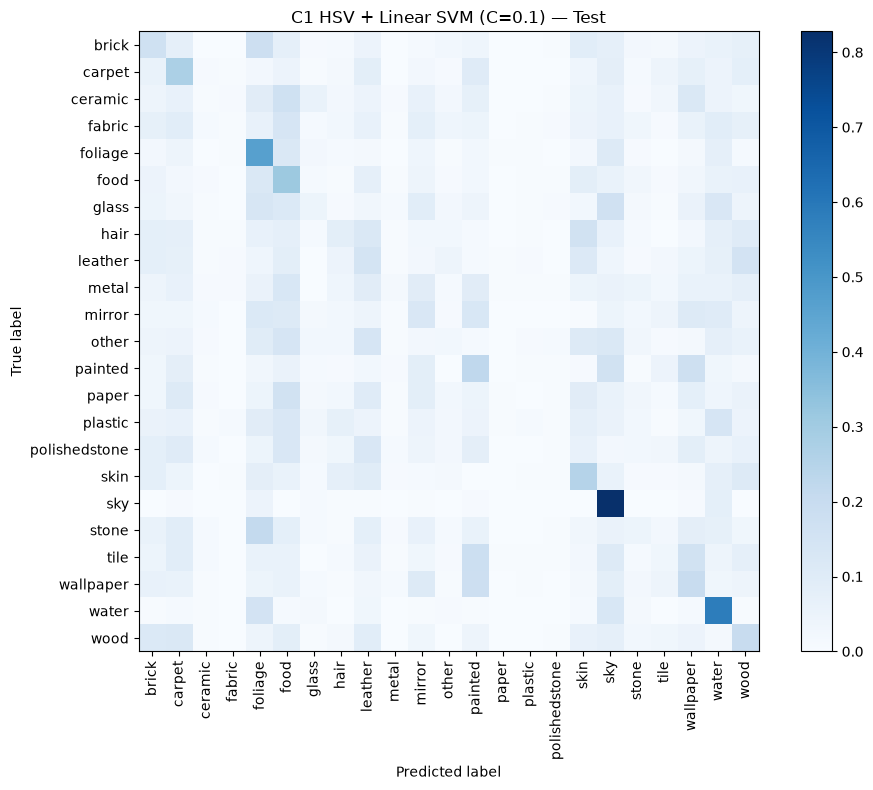

Đã ghi kết quả vào: D:\StupidCode\CS231\material-classification\outputs\c1_hsv_svm_20261118-115242


In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    labels=labels,
    display_labels=CLASS_NAMES,
    normalize="true",
    include_values=False,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
)
ax.set_title(f"C1 HSV + Linear SVM (C={best['C']}) — Test")
fig.tight_layout()
plt.show()

run_dir = local_path("OUTPUT_ROOT", "./outputs") / f"c1_hsv_svm_{time.strftime('%Y%m%d-%H%M%S')}"
run_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(run_dir / "confusion_matrix_test.png", dpi=150)

write_json(
    run_dir / "metrics.json",
    {
        "selected": {"C": best["C"], "val_macro_f1": round(float(best["score"]), 4)},
        "candidates": candidates,
        "test": {
            "accuracy": test_accuracy,
            "macro_f1": test_macro_f1,
            "per_class": {name: report[name] for name in CLASS_NAMES},
        },
    },
)
write_json(
    run_dir / "metadata.json",
    {
        "experiment": c1["experiment"]["name"],
        "source": "notebooks/c1_hsv_svm.ipynb",
        "dataset": {"id": cfg["dataset"]["id"], "revision": cfg["dataset"]["revision"]},
        "cache_signature": cache_signature(cfg),
        "seed": SEED,
        "classifier": SVM,
        "git": git_info(),
        "created_utc": utc_now(),
    },
)
print("Đã ghi kết quả vào:", run_dir)